In [1]:
#upload the dataset
from pathlib import Path

DATA_PATH = Path("DataCoSupplyChainDataset.csv")

if DATA_PATH.exists():
    print("Dataset found:", DATA_PATH.resolve())
else:
    print("Dataset NOT found. Put DataCoSupplyChainDataset.csv in the same folder as this notebook.")

Dataset found: C:\Users\Admin\Desktop\DS Lab1\DataCoSupplyChainDataset.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#import seaborn as sns

#  chart style
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "axes.axisbelow": True,
    "axes.edgecolor": "#898781", "axes.titleweight": "bold", "font.size": 11,
})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#898781"

In [3]:
# 1)upload the data

df = pd.read_csv(DATA_PATH, encoding="latin-1")
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 180519 | Columns: 53


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [4]:
# 2) data understanding

print("Order items (rows):", len(df))
print("Unique orders     :", df["Order Id"].nunique())
print("Unique customers  :", df["Customer Id"].nunique())
print("Unique products   :", df["Product Card Id"].nunique())

Order items (rows): 180519
Unique orders     : 65752
Unique customers  : 20652
Unique products   : 118


In [5]:
# check column types
df.dtypes.value_counts()

object     24
float64    15
int64      14
Name: count, dtype: int64

In [6]:
# check missing values and duplicates 

missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(1)})

,missing,percent
Product Description,180519,100.0
Order Zipcode,155679,86.2
Customer Lname,8,0.0
Customer Zipcode,3,0.0


In [7]:
print("Duplicated rows:", df.duplicated().sum())

Duplicated rows: 0


In [8]:
# check the relation between late_delivery_risk and delivery status the same ? 

pd.crosstab(df["Delivery Status"], df["Late_delivery_risk"])

Late_delivery_risk,0,1
Delivery Status,,
Advance shipping,41592,0
Late delivery,0,98977
Shipping canceled,7754,0
Shipping on time,32196,0


In [9]:
# data cleaning:

drop_cols = [
    "Customer Email", "Customer Password", "Customer Fname", "Customer Lname", "Customer Street",  # personal data
    "Product Description", "Order Zipcode", "Product Image",                                     # empty / not useful
]
clean = df.drop(columns=drop_cols).copy()

# remove space from columns
clean.columns = clean.columns.str.strip()

# convert dates
clean["order_date"] = pd.to_datetime(clean["order date (DateOrders)"])
clean["shipping_date"] = pd.to_datetime(clean["shipping date (DateOrders)"])
clean = clean.drop(columns=["order date (DateOrders)", "shipping date (DateOrders)"])

# new variable: delay in days (positive = late, negative = early)
clean["delay_days"] = clean["Days for shipping (real)"] - clean["Days for shipment (scheduled)"]

print("Shape after cleaning:", clean.shape)
print("Period:", clean["order_date"].min(), "->", clean["order_date"].max())

Shape after cleaning: (180519, 46)
Period: 2015-01-01 00:00:00 -> 2018-01-31 23:38:00


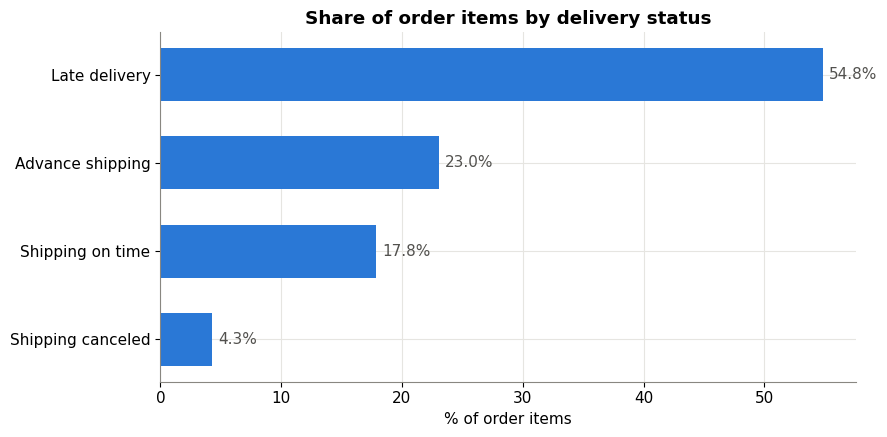

Overall late delivery rate: 54.8 %


In [10]:
# 4) KPI: late deliveries

# delivery status

# count how many order items are in each delivery status
status_counts = clean["Delivery Status"].value_counts()

# convert the counts to percentages
status_percent = status_counts / len(clean) * 100

# sort from smallest to largest (for the chart)
status_percent = status_percent.sort_values()

# create the chart
plt.barh(status_percent.index, status_percent.values, color=BLUE, height=0.6)

# add the percentage next to each bar
for i in range(len(status_percent)):
    value = status_percent.values[i]
    plt.text(value + 0.5, i, str(round(value, 1)) + "%", va="center", color="#52514e")

plt.title("Share of order items by delivery status")
plt.xlabel("% of order items")
plt.tight_layout()
plt.savefig("fig_delivery_status.png", dpi=150)
plt.show()

# overall late delivery rate
late_rate = clean["Late_delivery_risk"].mean() * 100
print("Overall late delivery rate:", round(late_rate, 1), "%")

More than half of the order items (54.8%) are delivered late, while only 17.8% arrive on time and 23% arrive early. 

This shows that late delivery is a big and frequent problem for the company, so it is a good KPI to monitor in real time.

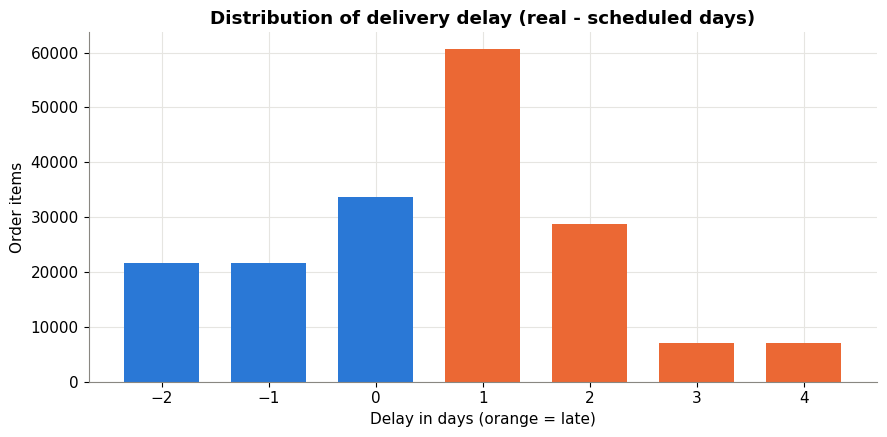

count    180519.000000
mean          0.565807
std           1.490966
min          -2.000000
25%           0.000000
50%           1.000000
75%           1.000000
max           4.000000
Name: delay_days, dtype: float64

In [11]:
# delay in days (real - scheduled)

# count how many order items have each delay value
delay_counts = clean["delay_days"].value_counts()

# sort by delay value
delay_counts = delay_counts.sort_index()

# choose a color for each bar: orange if late, blue if not late
colors = []
for delay in delay_counts.index:
    if delay > 0:
        colors.append(ORANGE)
    else:
        colors.append(BLUE)

# create the chart
plt.bar(delay_counts.index, delay_counts.values, color=colors, width=0.7)
plt.xticks(delay_counts.index)
plt.title("Distribution of delivery delay (real - scheduled days)")
plt.xlabel("Delay in days (orange = late)")
plt.ylabel("Order items")
plt.tight_layout()
plt.show()

# summary statistics of the delay
clean["delay_days"].describe()

The delay goes from -2 days (early) to +4 days (late), with an average of about 0.57 days and a median of 1 day. 

This means delays are very frequent but short: more than half of the deliveries are at least one day late but no order is more than 4 days late, so there are no extreme outliers to remove.

                late_rate  real_days  scheduled_days   items
Shipping Mode                                               
Standard Class       38.1       4.00             4.0  107752
Same Day             45.7       0.48             0.0    9737
Second Class         76.6       3.99             2.0   35216
First Class          95.3       2.00             1.0   27814


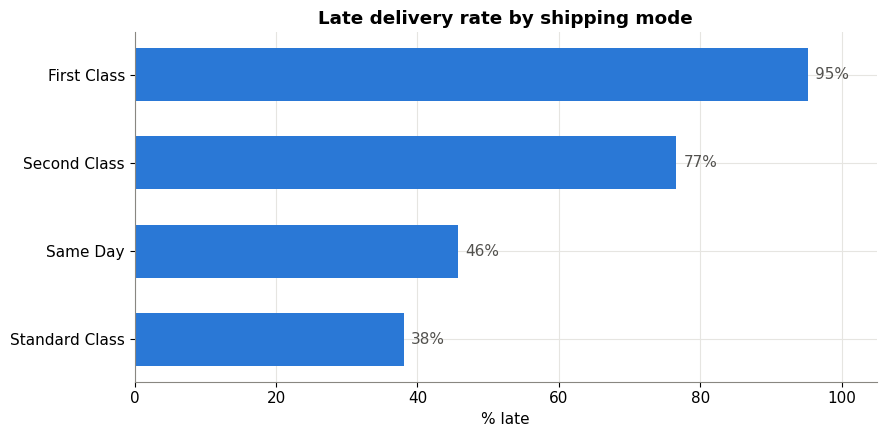

In [12]:
# late rate by shipping mode

# group the data by shipping mode and calculate each value separately
late_rate = clean.groupby("Shipping Mode")["Late_delivery_risk"].mean() * 100
real_days = clean.groupby("Shipping Mode")["Days for shipping (real)"].mean()
scheduled_days = clean.groupby("Shipping Mode")["Days for shipment (scheduled)"].mean()
items = clean.groupby("Shipping Mode")["Order Id"].count()

# put everything in one table
by_mode = pd.DataFrame({
    "late_rate": late_rate.round(1),
    "real_days": real_days.round(2),
    "scheduled_days": scheduled_days.round(2),
    "items": items
})

# sort from lowest to highest late rate
by_mode = by_mode.sort_values("late_rate")
print(by_mode)

# create the chart
plt.barh(by_mode.index, by_mode["late_rate"], color=BLUE, height=0.6)

# add the percentage next to each bar
for i in range(len(by_mode)):
    value = by_mode["late_rate"].values[i]
    plt.text(value + 1, i, str(round(value)) + "%", va="center", color="#52514e")

plt.title("Late delivery rate by shipping mode")
plt.xlabel("% late")
plt.xlim(0, 105)
plt.tight_layout()
plt.savefig("fig_shipping_mode.png", dpi=150)
plt.show()

First Class has the highest late rate (95%) because it is scheduled in 1 day but always takes 2 days,and Second Class is also often late (77%).

Standard Class has the lowest late rate (38%) because its scheduled time (4 days) matches the real shipping time, so the problem comes from unrealistic delivery promises and not from slow shipping.

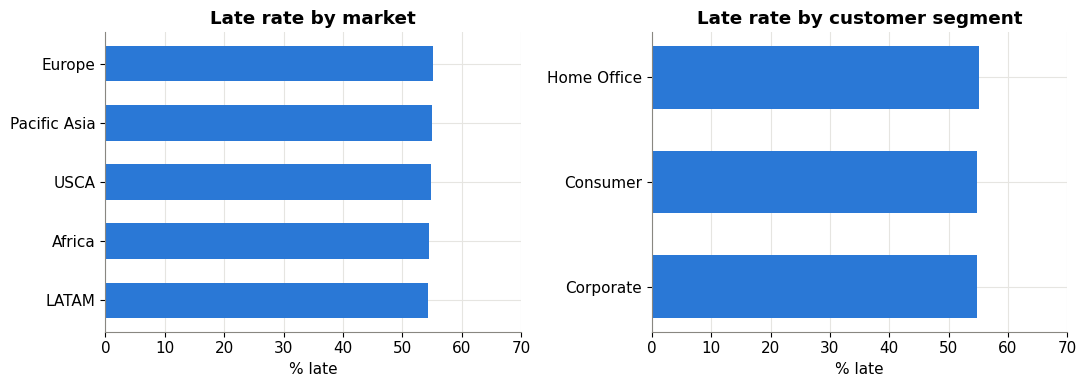

In [13]:
# late rate by market and by customer segment

# calculate the late rate for each market
market_rate = clean.groupby("Market")["Late_delivery_risk"].mean() * 100
market_rate = market_rate.sort_values()

# calculate the late rate for each customer segment
segment_rate = clean.groupby("Customer Segment")["Late_delivery_risk"].mean() * 100
segment_rate = segment_rate.sort_values()

# create a figure with 2 charts side by side
plt.figure(figsize=(11, 4))

# chart 1: market
plt.subplot(1, 2, 1)
plt.barh(market_rate.index, market_rate.values, color=BLUE, height=0.6)
plt.title("Late rate by market")
plt.xlabel("% late")
plt.xlim(0, 70)

# chart 2: customer segment
plt.subplot(1, 2, 2)
plt.barh(segment_rate.index, segment_rate.values, color=BLUE, height=0.6)
plt.title("Late rate by customer segment")
plt.xlabel("% late")
plt.xlim(0, 70)

plt.tight_layout()
plt.show()

The late rate is almost the same for all markets and all customer segments (around 55%).
This means that the location and the type of customer do not influence late deliveries.

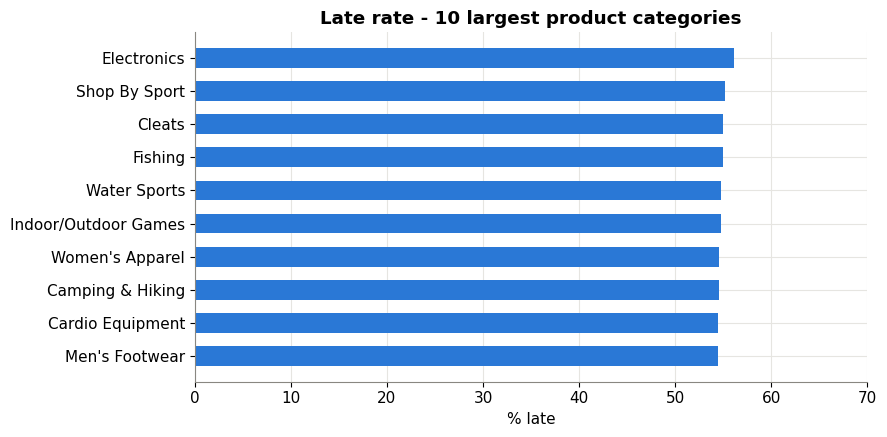

In [14]:
# late rate by product category (top 10 by volume)

# find the 10 categories with the most order items
category_counts = clean["Category Name"].value_counts()
top_10 = category_counts.head(10).index

# keep only the rows of these 10 categories
top_data = clean[clean["Category Name"].isin(top_10)]

# calculate the late rate for each category
category_rate = top_data.groupby("Category Name")["Late_delivery_risk"].mean() * 100
category_rate = category_rate.sort_values()

# create the chart
plt.barh(category_rate.index, category_rate.values, color=BLUE, height=0.6)
plt.title("Late rate - 10 largest product categories")
plt.xlabel("% late")
plt.xlim(0, 70)
plt.tight_layout()
plt.show()

All 10 largest product categories have a very similar late rate (between about 54% and 56%).So the product category is also not a factor that explains late deliveries.


Shipping Mode         Same Day  First Class  Second Class  Standard Class
Category Name                                                            
Camping & Hiking           5.4         15.0          19.4            60.2
Cardio Equipment           5.3         15.4          19.3            60.0
Cleats                     5.5         15.3          19.6            59.6
Electronics                5.6         15.8          19.0            59.6
Fishing                    5.0         15.7          19.1            60.2
Indoor/Outdoor Games       5.6         15.2          19.4            59.8
Men's Footwear             5.3         15.1          19.8            59.7
Shop By Sport              5.4         15.7          19.6            59.2
Water Sports               5.5         15.5          19.9            59.1
Women's Apparel            5.3         15.9          19.2            59.5


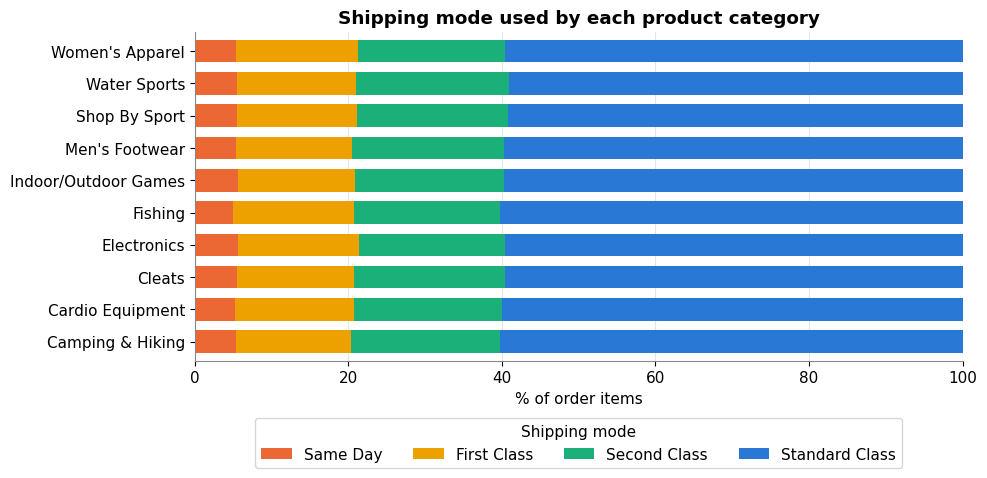

Shipping Mode         First Class  Same Day  Second Class  Standard Class
Category Name                                                            
Camping & Hiking             95.3      45.8          75.1            38.5
Cardio Equipment             95.7      43.7          75.9            38.0
Cleats                       95.7      44.9          77.1            38.2
Electronics                  94.2      48.3          78.1            39.7
Fishing                      95.0      46.9          77.3            38.1
Indoor/Outdoor Games         94.7      47.0          76.5            38.3
Men's Footwear               95.2      45.2          76.4            37.7
Shop By Sport                95.6      46.0          77.4            37.9
Water Sports                 95.7      43.8          76.7            37.7
Women's Apparel              95.1      45.7          75.5            37.7


In [15]:
# shipping mode used by each product category (top 10 categories)

# keep only the 10 biggest categories
category_counts = clean["Category Name"].value_counts()
top_10 = category_counts.head(10).index
top_data = clean[clean["Category Name"].isin(top_10)]

# count the order items for each category and each shipping mode
mode_table = pd.crosstab(top_data["Category Name"], top_data["Shipping Mode"])

# convert the counts to percentages (each row = 100%)
mode_percent = mode_table.div(mode_table.sum(axis=1), axis=0) * 100

# put the shipping modes in a logical order
mode_percent = mode_percent[["Same Day", "First Class", "Second Class", "Standard Class"]]
print(mode_percent.round(1))

# stacked bar chart
mode_colors = [ORANGE, "#eda100", "#1baf7a", BLUE]
mode_percent.plot(kind="barh", stacked=True, color=mode_colors, width=0.7, figsize=(10, 5))
plt.title("Shipping mode used by each product category")
plt.xlabel("% of order items")
plt.ylabel("")
plt.xlim(0, 100)
plt.legend(title="Shipping mode", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4)
plt.tight_layout()
plt.savefig("fig_category_mode.png", dpi=150)
plt.show()

# late rate for each category and each shipping mode
late_table = pd.pivot_table(top_data, index="Category Name", columns="Shipping Mode",
                            values="Late_delivery_risk", aggfunc="mean") * 100
print(late_table.round(1))

All 10 categories use almost the same mix of shipping modes: about 60% Standard Class, 19% Second Class, 15% First Class and 5% Same Day. For example, Electronics are mostly shipped with Standard Class (59.6%), like the other categories, and within each shipping mode their late rate is almost the same as for the other products, so the product category does not explain the delays.

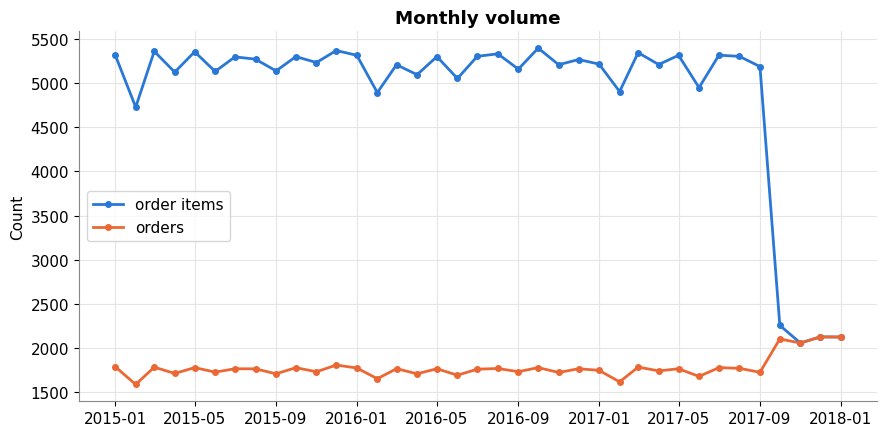

,items,orders,categories
order_date,,,
2017-06-01,4951,1676,24
2017-07-01,5318,1776,24
2017-08-01,5305,1768,24
2017-09-01,5189,1723,26
2017-10-01,2255,2101,20
2017-11-01,2055,2055,8
2017-12-01,2124,2124,14
2018-01-01,2123,2123,10


In [16]:
# 5) time analysis: monthly volume

# group the data by month (MS = month start)
monthly_data = clean.set_index("order_date").resample("MS")

# calculate each value separately
items = monthly_data["Order Id"].count()             # number of order items per month
orders = monthly_data["Order Id"].nunique()          # number of different orders per month
categories = monthly_data["Category Name"].nunique() # number of different categories per month

# put everything in one table
monthly = pd.DataFrame({
    "items": items,
    "orders": orders,
    "categories": categories
})

# create the chart with 2 lines
plt.plot(monthly.index, monthly["items"], color=BLUE, linewidth=2, marker="o", markersize=4, label="order items")
plt.plot(monthly.index, monthly["orders"], color=ORANGE, linewidth=2, marker="o", markersize=4, label="orders")
plt.title("Monthly volume")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.savefig("fig_monthly_volume.png", dpi=150)
plt.show()

# show the last 8 months
monthly.tail(8)

From January 2015 to September 2017 the monthly volume is stable (around 5,200 order items and 1,750 orders per month).

From October 2017 the number of order items drops to about 2,100 and becomes equal to the number of orders (only one product per order),
and the number of categories also decreases, so this last period looks different and may be a data quality problem.

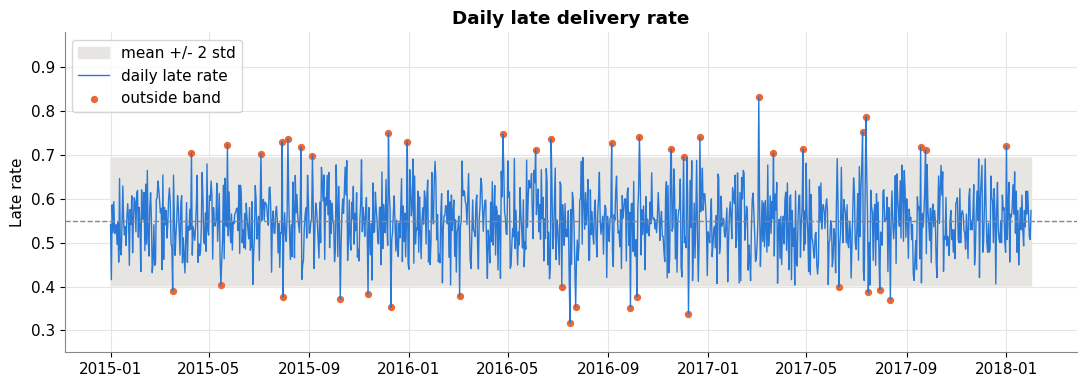

Mean: 0.549
Std: 0.073
Days outside the band: 42 of 1127
Average order items per day: 160.2
Average order items per hour: 6.7


In [17]:
# daily late delivery rate

# group the data by day
daily_data = clean.set_index("order_date").resample("D")

# calculate the late rate and the number of order items for each day
late_rate = daily_data["Late_delivery_risk"].mean()
items = daily_data["Late_delivery_risk"].count()

daily = pd.DataFrame({
    "late_rate": late_rate,
    "items": items
})

# mean and standard deviation of the daily late rate
mean = daily["late_rate"].mean()
std = daily["late_rate"].std()

# normal zone = mean +/- 2 standard deviations
upper = mean + 2 * std
lower = mean - 2 * std

# find the days outside the normal zone (possible anomalies)
too_high = daily["late_rate"] > upper
too_low = daily["late_rate"] < lower
outliers = daily[too_high | too_low]

# create the chart
plt.figure(figsize=(11, 4))
plt.fill_between(daily.index, lower, upper, color="#e6e5e1", label="mean +/- 2 std")
plt.plot(daily.index, daily["late_rate"], color=BLUE, linewidth=1, label="daily late rate")
plt.axhline(mean, color=GREY, linestyle="--", linewidth=1)
plt.scatter(outliers.index, outliers["late_rate"], color=ORANGE, s=18, label="outside band")
plt.title("Daily late delivery rate")
plt.ylabel("Late rate")
plt.ylim(0.25, 0.98)
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig("fig_daily_late_rate.png", dpi=150)
plt.show()

# print the results
print("Mean:", round(mean, 3))
print("Std:", round(std, 3))
print("Days outside the band:", len(outliers), "of", len(daily))

items_per_day = daily["items"].mean()
items_per_hour = items_per_day / 24
print("Average order items per day:", round(items_per_day, 1))
print("Average order items per hour:", round(items_per_hour, 1))

The daily late rate stays around 55% with no clear trend over time, and 42 days out of 1,127 are outside the mean ± 2 std band, which can be seen as possible anomalies. 

There are about 160 order items per day (about 7 per hour), so the stream will need to be replayed faster to simulate real-time data.

           items  late_rate
order_day                  
Monday     25786      55.05
Tuesday    25622      54.30
Wednesday  25587      54.76
Thursday   25752      55.01
Friday     25925      55.17
Saturday   25901      54.40
Sunday     25946      55.11


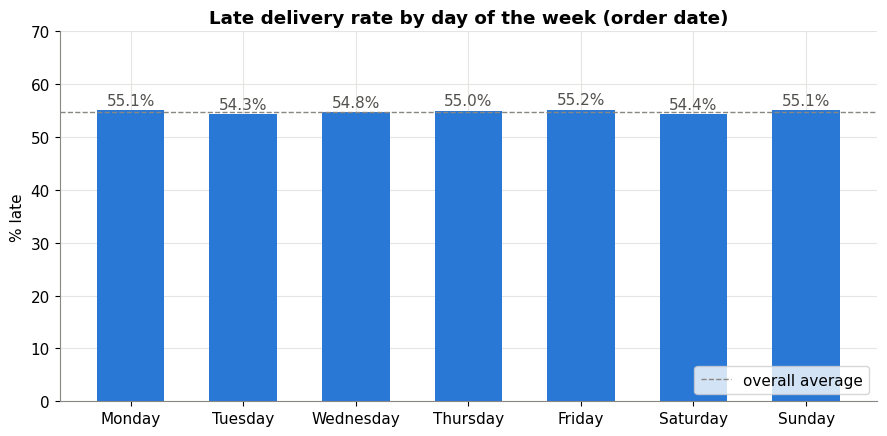

p-value: 0.251
The difference between days is NOT significant


In [18]:
#Late delivery rate by day of the week

# get the name of the day from the order date (Monday, Tuesday, ...)
clean["order_day"] = clean["order_date"].dt.day_name()

days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# late rate and number of order items for each day of the week
day_rate = clean.groupby("order_day")["Late_delivery_risk"].mean() * 100
day_count = clean.groupby("order_day")["Order Id"].count()

# put the days in the normal order (Monday first)
day_rate = day_rate.reindex(days_order)
day_count = day_count.reindex(days_order)

day_table = pd.DataFrame({
    "items": day_count,
    "late_rate": day_rate.round(2)
})
print(day_table)

# bar chart
plt.figure(figsize=(9, 4.5))
plt.bar(day_rate.index, day_rate.values, color=BLUE, width=0.6)
plt.axhline(clean["Late_delivery_risk"].mean() * 100, color=GREY, linestyle="--", linewidth=1, label="overall average")
for i in range(len(day_rate)):
    value = day_rate.values[i]
    plt.text(i, value + 1, str(round(value, 1)) + "%", ha="center", color="#52514e")
plt.title("Late delivery rate by day of the week (order date)")
plt.ylabel("% late")
plt.ylim(0, 70)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("fig_weekday.png", dpi=150)
plt.show()

# chi-square test: is the difference between days statistically significant?
from scipy.stats import chi2_contingency
day_late_table = pd.crosstab(clean["order_day"], clean["Late_delivery_risk"])
result = chi2_contingency(day_late_table)
p_value = result[1]
print("p-value:", round(p_value, 3))
if p_value < 0.05:
    print("The difference between days is significant")
else:
    print("The difference between days is NOT significant")

The late rate is almost the same every day of the week, between 54.3% (Tuesday) and 55.2% (Friday), and the chi-square test gives a p-value of 0.25, so there is no specific day when delays happen more often. The number of orders is also almost the same every day, even on weekends, which suggests that the dataset is partly synthetic.

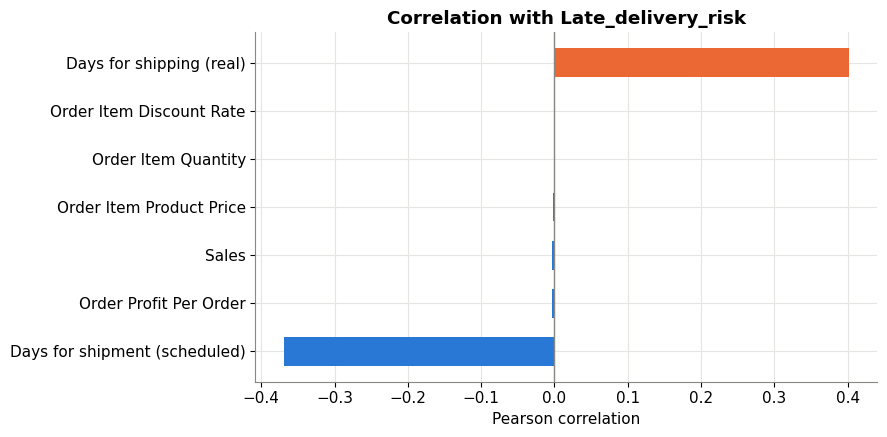

Days for shipment (scheduled)   -0.369
Order Profit Per Order          -0.004
Sales                           -0.004
Order Item Product Price        -0.002
Order Item Quantity             -0.000
Order Item Discount Rate         0.000
Days for shipping (real)         0.401
Name: Late_delivery_risk, dtype: float64


In [19]:
# 6) correlation of numeric variables with late delivery

# list of numeric columns to compare
num_cols = ["Late_delivery_risk", "Days for shipping (real)", "Days for shipment (scheduled)",
            "Order Item Quantity", "Order Item Discount Rate", "Order Item Product Price",
            "Sales", "Order Profit Per Order"]

# calculate the correlation table
corr_table = clean[num_cols].corr()

# keep only the correlation with Late_delivery_risk
corr = corr_table["Late_delivery_risk"]

# remove Late_delivery_risk itself (its correlation with itself is always 1)
corr = corr.drop("Late_delivery_risk")

# sort from smallest to largest
corr = corr.sort_values()

# choose a color for each bar: orange if positive, blue if negative
colors = []
for value in corr.values:
    if value > 0:
        colors.append(ORANGE)
    else:
        colors.append(BLUE)

# create the chart
plt.barh(corr.index, corr.values, color=colors, height=0.6)
plt.axvline(0, color=GREY, linewidth=1)
plt.title("Correlation with Late_delivery_risk")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

print(corr.round(3))

Late delivery is only correlated with the shipping times: positively with the real shipping days (+0.40) and negatively with the scheduled days (-0.37).
Financial variables like price, quantity, discount, sales and profit have almost no correlation (close to 0), so they do not explain late deliveries.

In [20]:
# 7) baseline 1: batch KPI (classic ERP daily report)

# group the data by day
daily_data = clean.set_index("order_date").resample("D")

# calculate the daily KPIs
items = daily_data["Order Id"].count()
late_rate = daily_data["Late_delivery_risk"].mean()
avg_delay = daily_data["delay_days"].mean()
sales = daily_data["Sales"].sum()

batch_kpi = pd.DataFrame({
    "items": items,
    "late_rate": late_rate,
    "avg_delay_days": avg_delay,
    "sales": sales
})

# Baseline 2 (preview): fixed threshold
# alert if more than 65% of the deliveries of the day are late
threshold = 0.65
batch_kpi["alert_fixed"] = batch_kpi["late_rate"] > threshold

# Baseline 3 (preview): z-score
# z = (value - mean) / standard deviation
mean = batch_kpi["late_rate"].mean()
std = batch_kpi["late_rate"].std()
batch_kpi["z"] = (batch_kpi["late_rate"] - mean) / std

# alert if z is bigger than 2 or smaller than -2
batch_kpi["alert_z"] = (batch_kpi["z"] > 2) | (batch_kpi["z"] < -2)

# count the alerts
print("Days with fixed threshold alert:", batch_kpi["alert_fixed"].sum())
print("Days with z-score alert:", batch_kpi["alert_z"].sum())

# show the first 10 days
batch_kpi.head(10).round(3)

Days with fixed threshold alert: 95
Days with z-score alert: 42


,items,late_rate,avg_delay_days,sales,alert_fixed,z,alert_z
order_date,,,,,,,
2015-01-01,168,0.542,0.458,32806.091,False,-0.096,False
2015-01-02,154,0.416,0.240,29818.211,False,-1.826,False
2015-01-03,179,0.587,0.670,36348.711,False,0.520,False
2015-01-04,191,0.524,0.267,35738.971,False,-0.345,False
2015-01-05,160,0.594,0.738,31067.911,False,0.619,False
2015-01-06,169,0.521,0.675,33395.711,False,-0.384,False
2015-01-07,161,0.528,0.447,32923.221,False,-0.284,False
2015-01-08,194,0.541,0.598,37590.171,False,-0.102,False
2015-01-09,129,0.496,0.450,26004.931,False,-0.721,False


In [21]:
# 8) save clean dataset

clean = clean.sort_values("order_date").reset_index(drop=True)
clean.to_csv("dataco_clean.csv", index=False)
print("Saved dataco_clean.csv:", clean.shape)

Saved dataco_clean.csv: (180519, 47)
